# 1. Linear Regression: Predicting Car Fuel Efficiency (Auto MPG)

**Dataset documentation:** https://archive.ics.uci.edu/dataset/9/auto+mpg
**Data file:** `data/mpg.csv` (the UCI Auto MPG data, 398 cars, 1970-1982)

## 1.1 Objectives (Business Understanding)

**Business context:** An importer / fleet buyer / regulator wants a quick estimate of a car's fuel efficiency from its technical specification, before expensive road tests are done. Fuel economy drives running costs and emissions-compliance decisions, so an accurate early estimate helps with purchasing and pricing.

**Prediction task:** predict how many miles per gallon a car achieves, and identify which specifications drive it.

**Target variable:** `mpg` (miles per gallon, continuous).
**Predictors:** cylinders, displacement, horsepower, weight, acceleration, model year and origin (USA / Europe / Japan).
**Success criterion:** test RMSE of roughly 3 mpg or better and R² above 0.8, judged on data the model has not seen. I also ask whether a polynomial term improves the model.

## 1.2 Data Exploration (Data Understanding & Preparation)

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

os.makedirs('plots', exist_ok=True)
df = pd.read_csv('data/mpg.csv')
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [16]:
df.info()
print('\nMissing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB

Missing values per column:
horsepower    6
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


**Comment:** 398 cars and 9 columns. Only `horsepower` has missing values (6 rows, 1.5%), so imputing with the median is safer than dropping rows. `name` is an identifier (almost unique per car) and is not usable as a predictor. The target `mpg` ranges from 9 to 46.6 with a mean of 23.5.

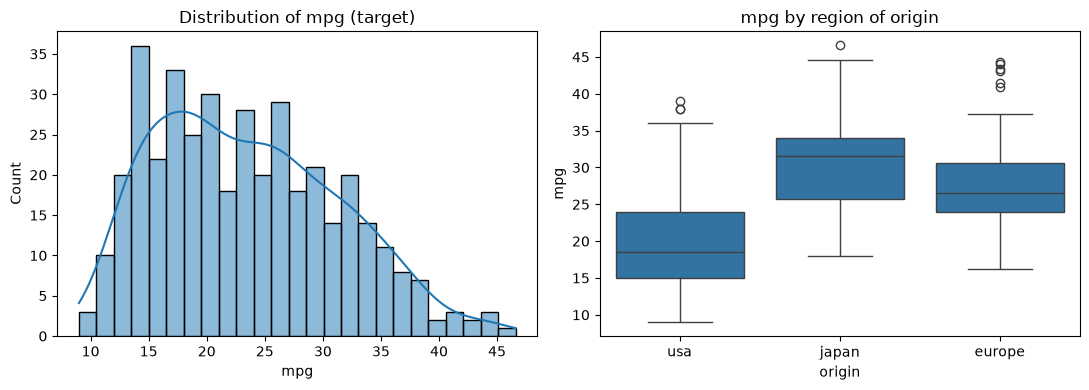

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['mpg'], bins=25, kde=True, ax=ax[0])
ax[0].set_title('Distribution of mpg (target)')
sns.boxplot(data=df, x='origin', y='mpg', ax=ax[1])
ax[1].set_title('mpg by region of origin')
plt.tight_layout(); plt.savefig('plots/1_mpg_distribution.png', dpi=120); plt.show()

**Comment:** `mpg` is mildly right-skewed (skew about 0.46), with most cars between 15 and 30 mpg, so no transformation is needed. The boxplot shows a clear origin effect: US cars average about 20 mpg, European cars about 28 and Japanese cars about 30. Origin is therefore worth keeping as a predictor.

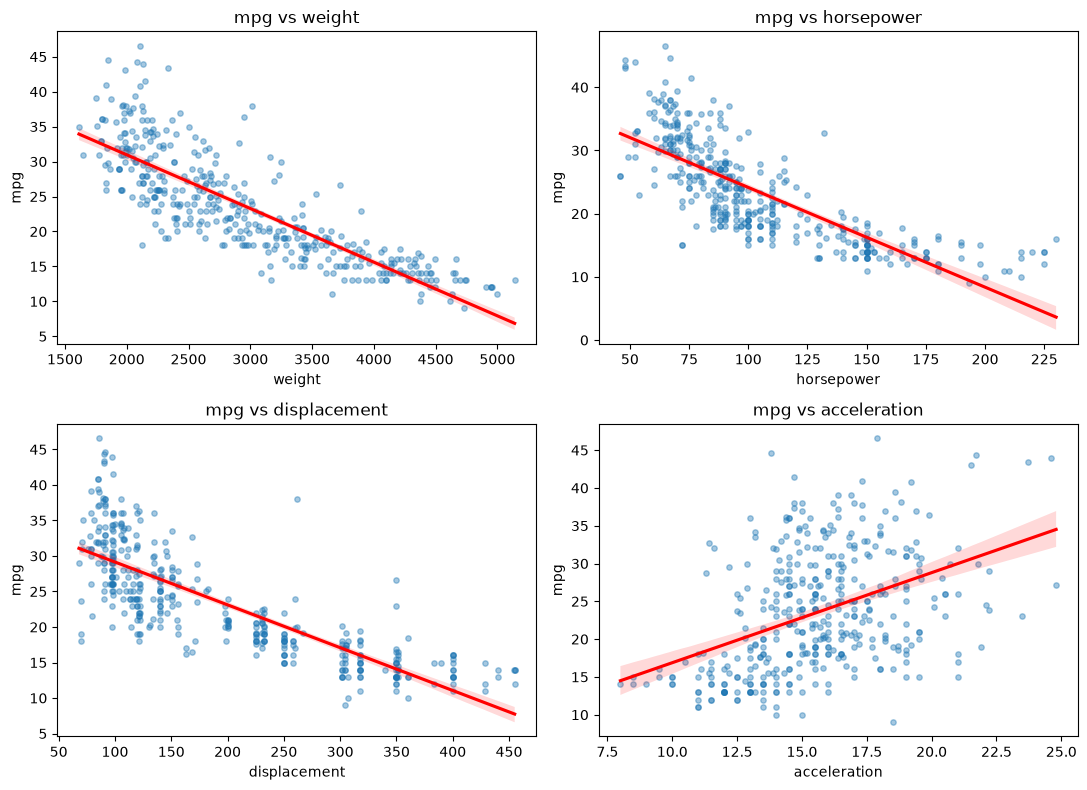

In [18]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a, col in zip(ax.ravel(), ['weight', 'horsepower', 'displacement', 'acceleration']):
    sns.regplot(data=df, x=col, y='mpg', ax=a, scatter_kws={'alpha': 0.4, 's': 15}, line_kws={'color': 'red'})
    a.set_title(f'mpg vs {col}')
plt.tight_layout(); plt.savefig('plots/1_scatter_mpg_vs_features.png', dpi=120); plt.show()

**Comment:** Heavier, more powerful cars with bigger engines get fewer mpg, which is the expected direction. The `weight` panel is clearly **curved**: the points bend above the red straight line at both ends and fall below it in the middle. This is the main reason to test a polynomial (squared) term. `acceleration` has only a weak positive relationship.

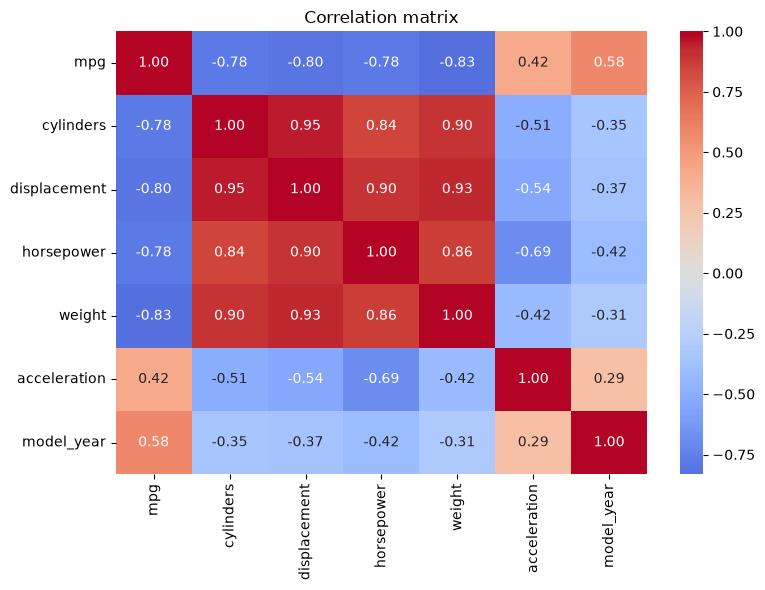

In [19]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=['name', 'origin']).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.tight_layout(); plt.savefig('plots/1_correlation_heatmap.png', dpi=120); plt.show()

**Comment:** `weight` (-0.83), `displacement` (-0.80), `cylinders` (-0.78) and `horsepower` (-0.77) are all strongly negatively correlated with `mpg`. They are also highly correlated with each other (weight vs displacement is 0.93), so multicollinearity is likely. This can make individual coefficients unstable, but it does not harm prediction accuracy much. `model_year` (+0.58) shows efficiency improving over time.

**Data preparation:** fill the 6 missing horsepower values with the median, drop the car `name` (an identifier, not a predictor) and one-hot encode `origin`.

In [20]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df = df.drop(columns='name')
df = pd.get_dummies(df, columns=['origin'], drop_first=True, dtype=int)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,18.0,8,307.0,130.0,3504,12.0,70,0,1
1,15.0,8,350.0,165.0,3693,11.5,70,0,1
2,18.0,8,318.0,150.0,3436,11.0,70,0,1
3,16.0,8,304.0,150.0,3433,12.0,70,0,1
4,17.0,8,302.0,140.0,3449,10.5,70,0,1


## 1.3 Modeling

In [21]:
# Define X and y, then split (random_state fixed so results can be replicated)
X = df.drop(columns='mpg')
y = df['mpg']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

results = {}
def evaluate(name, model, cols, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr
    Xte = X_test if Xte is None else Xte
    cv_r2 = cross_val_score(model, Xtr[cols], y_train, cv=5, scoring='r2')
    cv_rmse = -cross_val_score(model, Xtr[cols], y_train, cv=5, scoring='neg_root_mean_squared_error')
    model.fit(Xtr[cols], y_train)
    pred = model.predict(Xte[cols])
    results[name] = {'CV R2': cv_r2.mean(), 'CV RMSE': cv_rmse.mean(),
                     'Test R2': r2_score(y_test, pred),
                     'Test RMSE': np.sqrt(mean_squared_error(y_test, pred))}
    return model, pred

Train: (318, 8)  Test: (80, 8)


### Model 1: simple linear regression (weight only)

In [22]:
m1, pred1 = evaluate('1: weight only', LinearRegression(), ['weight'])
print('Intercept:', round(m1.intercept_, 2), '  Coefficient (weight):', round(m1.coef_[0], 5))

Intercept: 46.78   Coefficient (weight): -0.00781


### Model 2: multiple linear regression (all features)

In [23]:
all_cols = list(X.columns)
m2, pred2 = evaluate('2: all features', LinearRegression(), all_cols)
coefs = pd.Series(m2.coef_, index=all_cols).round(4)
print('Intercept:', round(m2.intercept_, 2))
coefs

Intercept: -18.91


cylinders      -0.1657
displacement    0.0198
horsepower     -0.0146
weight         -0.0070
acceleration    0.0680
model_year      0.8260
origin_japan   -0.2758
origin_usa     -2.9469
dtype: float64

**Interpreting Model 2 (units: per 1 unit change, all else equal):** each extra year of model age adds about +0.83 mpg, which is the strongest effect and reflects efficiency improvements after the 1973 oil crisis. Each extra 100 lb of weight costs about 0.7 mpg. Compared with the reference group (Europe), US cars are about 2.9 mpg lower. Displacement and cylinders have small or counter-intuitive coefficients because they are collinear with weight and horsepower, so I would not interpret them individually.

### Polynomial term: is it appropriate?
The weight scatter plot above bends (the fit is not a straight line), so a squared term is worth testing. I add `weight_sq` (weight in 1000s of lbs, squared) and keep everything else the same.

In [24]:
Xtr_p, Xte_p = X_train.copy(), X_test.copy()
for d in (Xtr_p, Xte_p):
    d['weight_k'] = d['weight'] / 1000          # weight in 1000 lbs keeps coefficients readable
    d['weight_sq'] = d['weight_k'] ** 2

# Model 3: simple polynomial regression (weight + weight^2)
m3, pred3 = evaluate('3: weight + weight^2', LinearRegression(), ['weight_k', 'weight_sq'], Xtr_p, Xte_p)
print('Model 3  intercept:', round(m3.intercept_, 2), ' coefs [weight_k, weight_sq]:', m3.coef_.round(3))

# Model 4: all features + weight^2
poly_cols = all_cols + ['weight_sq']
m4, pred4 = evaluate('4: all features + weight^2', LinearRegression(), poly_cols, Xtr_p, Xte_p)
print('Model 4  coefficient on weight_sq:', round(pd.Series(m4.coef_, index=poly_cols)['weight_sq'], 3))

Model 3  intercept: 62.39  coefs [weight_k, weight_sq]: [-18.409   1.668]
Model 4  coefficient on weight_sq: 2.277


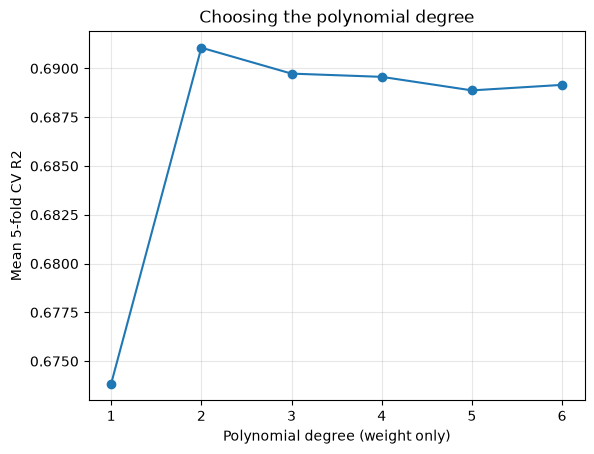

[np.float64(0.674), np.float64(0.691), np.float64(0.69), np.float64(0.69), np.float64(0.689), np.float64(0.689)]


In [25]:
# How does CV R2 change with polynomial degree on weight alone?
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
degs = range(1, 7)
scores = [cross_val_score(make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()),
                          X_train[['weight']] / 1000, y_train, cv=5, scoring='r2').mean() for d in degs]
plt.plot(list(degs), scores, marker='o'); plt.xlabel('Polynomial degree (weight only)'); plt.ylabel('Mean 5-fold CV R2')
plt.title('Choosing the polynomial degree'); plt.grid(alpha=.3)
plt.savefig('plots/1_poly_degree.png', dpi=120); plt.show()
print([round(s, 3) for s in scores])

**Is polynomial regression appropriate?** Yes, but only a modest one. The weight-only CV R² rises from 0.674 (degree 1) to its peak of about 0.691 at degree 2, then stays flat or declines for higher degrees. So the curvature is real, yet a quadratic captures it and higher degrees add nothing but complexity and overfitting risk. I therefore keep degree 2 only.

## 1.4 Evaluation & Conclusion

In [26]:
res = pd.DataFrame(results).T.round(3)
res

,CV R2,CV RMSE,Test R2,Test RMSE
1: weight only,0.674,4.476,0.723,3.859
2: all features,0.805,3.460,0.845,2.888
3: weight + weight^2,0.691,4.343,0.755,3.626
4: all features + weight^2,0.840,3.122,0.882,2.521


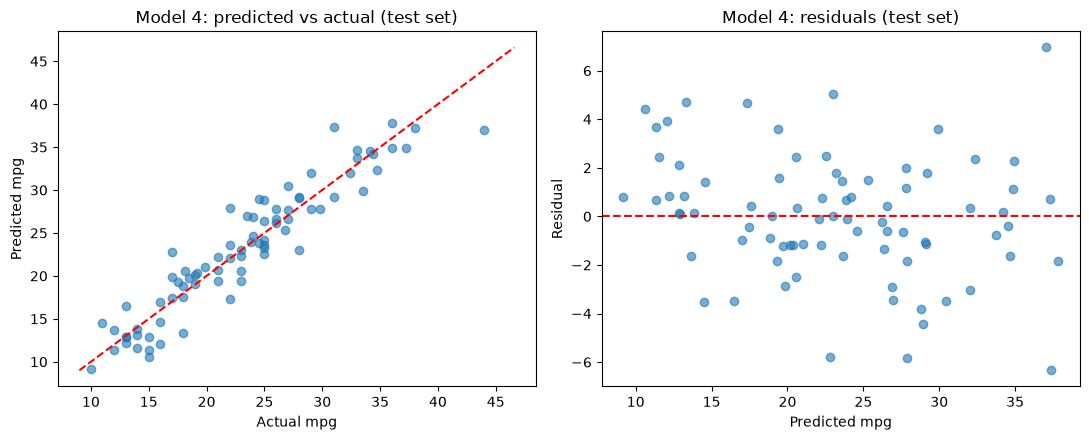

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test, pred4, alpha=.6); ax[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax[0].set_xlabel('Actual mpg'); ax[0].set_ylabel('Predicted mpg'); ax[0].set_title('Model 4: predicted vs actual (test set)')
ax[1].scatter(pred4, y_test - pred4, alpha=.6); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('Predicted mpg'); ax[1].set_ylabel('Residual'); ax[1].set_title('Model 4: residuals (test set)')
plt.tight_layout(); plt.savefig('plots/1_best_model_diagnostics.png', dpi=120); plt.show()

### Evaluation
| Model | CV R² | Test R² | Test RMSE (mpg) |
|---|---|---|---|
| 1: weight only | 0.674 | 0.723 | 3.86 |
| 2: all features | 0.805 | 0.845 | 2.89 |
| 3: weight + weight² | 0.691 | 0.755 | 3.63 |
| 4: all features + weight² | **0.840** | **0.882** | **2.52** |

**Comment on the plots:** predicted vs actual values lie close to the red diagonal for the test set. The residual plot shows no strong pattern around zero, though a little spread remains at the low-mpg (heavy car) end, so the model is slightly less reliable there.

### Conclusion
- The squared weight term helps in both settings: it lifts the simple model's test R² from 0.72 to 0.76, and the full model's from 0.85 to 0.88 (CV R² 0.805 to 0.840). The positive `weight_sq` coefficient confirms that the mpg loss per extra pound shrinks for very heavy cars.
- **Model 4 meets the objective:** it predicts mpg to within about 2.5 mpg (RMSE) on unseen cars and explains about 88% of the variance. The close agreement of CV and test results suggests it is not overfitted.
- **Limitations:** the data is from 1970 to 1982, so it should not be used for modern cars. Collinearity means individual coefficients (other than model year and origin) should be interpreted with care. The test set is only 80 cars, so the test figures are somewhat noisy.